# Probing LittleLearner's knowledge boundary

**Paper:** *LittleLearner: Language Models Under Pedagogically Controlled Knowledge Exposure* (arXiv 2608.13545). Models: https://littlelearner-ll.github.io/ → `huggingface.co/littlelearner`.

**Claim under test.** LittleLearner, trained only on K-5-filtered text, "knows" K-5 content but has clear knowledge boundaries above Grade 5, while the matched UNFILTERED model, trained the same way on unfiltered data, does not show such a drop.

**What's new here.** The paper validates this on its own benchmarks (MathCAMPS, Jeopardy, CommonCoreText). This notebook tests the claim on **a grade-tagged item set you build yourself**, scoring both released base models by log-likelihood. You need no generation and no prompt tuning.

**Hypothesis (write yours down before running):**
- H1: LittleLearner's accuracy drops to near chance after Grade 5, and the drop is much larger than UNFILTERED's.
- H0: the drop is similar for both models, so it reflects item difficulty, not filtering.

In [ ]:
import json, math, time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM

DEVICE = "cuda" if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else "cpu")
DTYPE = torch.bfloat16 if DEVICE == "cuda" else torch.float32
print(DEVICE, DTYPE)

TEAL, VIOLET, ORANGE_BAND = "#00939C", "#6250D6", "#FBEFE8"   # teal/violet pass the CVD + contrast checks
INK, MUTED, GRID = "#33414D", "#5B6B78", "#D9E1E6"
plt.rcParams.update({
    "figure.dpi": 120, "savefig.dpi": 200, "savefig.bbox": "tight",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK, "text.color": INK,
    "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.axisbelow": True, "font.size": 10,
})

FIG_DIR, CACHE_DIR = Path("figs"), Path("cache")
FIG_DIR.mkdir(exist_ok=True); CACHE_DIR.mkdir(exist_ok=True)

cuda torch.bfloat16


In [ ]:
SIZE = "0.6b"     # Change Models: "0.6b" -> "1.3b" -> "5b"
MODELS = {
    "LittleLearner": f"littlelearner/littlelearner-{SIZE}-base",
    "Unfiltered":    f"littlelearner/unfiltered-{SIZE}-base",
}
MODEL_COLORS = {"LittleLearner": TEAL, "Unfiltered": VIOLET}
MODEL_MARKERS = {"LittleLearner": "o", "Unfiltered": "s"} 
METRIC = "correct_norm" # Does not depend on answer length (normalized)

## 1. Items

**Unit = one multiple-choice item** with a grade tag. Store them as JSONL, one item per line:

```json
{"id": "sci-g7-012", "grade": 7, "subject": "science", "topic": "cells",
 "context": "Question: Which organelle releases energy from food in a cell?\nAnswer:",
 "options": [" mitochondria", " nucleus", " cell wall", " vacuole"], "answer": 0,
 "source": "adapted from SciQ #4411 (CC BY-NC 3.0)"}
```

- `context` is everything before the answer. `options` are the possible continuations, each starting with a space. `answer` is the index of the correct option.
- `grade`: 0 = K, 1-12. The **ground truth is the curriculum's grade**, not your intuition. Record where it comes from in `source`.

In [ ]:
ITEMS_PATH = Path("data/items.jsonl") 

def load_items(path):
    items = [json.loads(l) for l in Path(path).read_text().splitlines() if l.strip()]
    df = pd.DataFrame(items)

    #Check the dataframe: missing columns, duplicate ids, answer index out of range
    for col in ["id", "grade", "context", "options", "answer"]:
        assert col in df.columns, f"missing column {col}"
    assert df["id"].is_unique, "duplicate ids"
    bad = df[[not (0 <= a < len(o)) for a, o in zip(df.answer, df.options)]]
    assert bad.empty, f"answer index out of range: {bad.id.tolist()}"
    for col, default in [("subject", "unknown"), ("topic", ""), ("source", "unknown")]:
        if col not in df.columns:
            df[col] = default
    # Distinguish K5 vs BeyondK5 
    df["band"] = np.where(df["grade"] <= 5, "K5", "BeyondK5")
    df["n_options"] = df["options"].map(len)
    return df

items = load_items(ITEMS_PATH)
print(len(items), "items")
items.groupby(["grade", "subject"]).size().unstack(fill_value=0)

252 items


subject,math,science
grade,,
0,16,12
1,16,12
2,16,12
3,16,12
4,16,12
5,16,12
6,16,12
7,16,12
8,16,12


## 2. Scoring by log-likelihood

For each option we compute $\log p(\text{option} \mid \text{context})$ under the model, summed over the option's tokens. The model "answers" with the highest-scoring option. We report two variants:

- **acc**: argmax of the summed log-prob. Biased toward short options.
- **acc_norm**: argmax of log-prob **per byte** of the option. This is the main metric. The two models use **different tokenizers** (LittleLearner's 64k BPE was trained only on K-5 text), so per-token numbers are not comparable across models, but per-byte numbers are.

Context and option are tokenized separately and concatenated, like lm-evaluation-harness does, so every option is scored on exactly the same context tokens.

In [ ]:
def load_model(repo):
    tok = AutoTokenizer.from_pretrained(repo)
    model = AutoModelForCausalLM.from_pretrained(repo, dtype=DTYPE).to(DEVICE).eval()
    return tok, model

@torch.no_grad()
def option_logprobs(tok, model, context, options):
    # Returns one summed log-prob per option.
    ctx_ids = tok(context, add_special_tokens=False)["input_ids"]
    scores = []
    for opt in options:
        opt_ids = tok(opt, add_special_tokens=False)["input_ids"]
        ids = torch.tensor([ctx_ids + opt_ids], device=DEVICE)
        logits = model(ids).logits[0, :-1].float()
        logp = torch.log_softmax(logits, dim=-1)
        target = ids[0, 1:]
        tok_lp = logp[torch.arange(len(target)), target][-len(opt_ids):]
        scores.append(tok_lp.sum().item())
    return scores

def score_items(tok, model, items, model_name, cache=True):

    #Caching
    path = CACHE_DIR / f"{model_name}_{SIZE}.jsonl"
    done = {}
    if cache and path.exists():
        done = {r["id"]: r for r in map(json.loads, path.read_text().splitlines())}

    t0 = time.time()
    with open(path, "a") as f:
        for i, row in enumerate(items.itertuples()):
            if row.id in done:
                continue
            lp = option_logprobs(tok, model, row.context, row.options)
            rec = {"id": row.id, "model": model_name, "logprobs": lp}
            done[row.id] = rec
            f.write(json.dumps(rec) + "\n")
            if (i + 1) % 25 == 0:
                print(f"{model_name}: {i + 1}/{len(items)}  ({time.time() - t0:.0f}s)")
    return pd.DataFrame([done[i] for i in items.id])

In [26]:
raw_scores = []
for name in MODELS:
    tok, model = load_model(MODELS[name])
    raw_scores.append(score_items(tok, model, items, name))
    del model
    if DEVICE == "cuda":
        torch.cuda.empty_cache()
raw_scores = pd.concat(raw_scores, ignore_index=True)

Loading weights: 100%|██████████| 486/486 [00:00<00:00, 15765.50it/s]


LittleLearner: 25/252  (3s)
LittleLearner: 50/252  (6s)
LittleLearner: 75/252  (9s)
LittleLearner: 100/252  (12s)
LittleLearner: 125/252  (16s)
LittleLearner: 150/252  (19s)
LittleLearner: 175/252  (22s)
LittleLearner: 200/252  (25s)
LittleLearner: 225/252  (28s)
LittleLearner: 250/252  (31s)


Loading weights: 100%|██████████| 486/486 [00:00<00:00, 15528.19it/s]


Unfiltered: 25/252  (3s)
Unfiltered: 50/252  (6s)
Unfiltered: 75/252  (9s)
Unfiltered: 100/252  (12s)
Unfiltered: 125/252  (16s)
Unfiltered: 150/252  (19s)
Unfiltered: 175/252  (22s)
Unfiltered: 200/252  (25s)
Unfiltered: 225/252  (28s)
Unfiltered: 250/252  (31s)


In [ ]:
def add_predictions(items, raw):

    df = raw.merge(items, on="id")
    byte_len = df["options"].map(lambda os: np.array([max(len(o.encode()), 1) for o in os]))
    lp = df["logprobs"].map(np.array)
    # Select the option with the highest log-probability
    df["pred"] = lp.map(np.argmax)
    # Select the option with the highest log-probability per byte
    df["pred_norm"] = [int(np.argmax(l / b)) for l, b in zip(lp, byte_len)]
    # Check if the predictions are correct
    df["correct"] = df["pred"] == df["answer"]
    df["correct_norm"] = df["pred_norm"] == df["answer"]
    df["chance"] = 1 / df["n_options"]
    return df

res = add_predictions(items, raw_scores)
res.groupby(["model", "band"])[["correct", "correct_norm", "chance"]].mean().round(3)

correct  correct_norm  chance
model         band                                   
LittleLearner BeyondK5    0.476         0.488    0.25
              K5          0.792         0.774    0.25
Unfiltered    BeyondK5    0.583         0.583    0.25
              K5          0.720         0.744    0.25

### 2a. Sanity checks

**Option-only baseline.** Score each option with an empty context (`"Answer:"`). If accuracy is already high without the question, your options leak the answer through frequency or length.

In [30]:
BASELINE_CONTEXT = "Answer:"

# Option-only scoring, cached like the main run.
baseline_scores = []
for name in MODELS:
    tok, model = load_model(MODELS[name])
    optonly = score_items(tok, model, items.assign(context=BASELINE_CONTEXT), f"{name}-optonly")
    baseline_scores.append(optonly.assign(model=name))
    del model
    if DEVICE == "cuda":
        torch.cuda.empty_cache()
base = add_predictions(items, pd.concat(baseline_scores, ignore_index=True))

# 1. Option-only baseline: should sit near chance. If not, the options give the answer away.
display(pd.concat({
    "with question": res.groupby(["model", "band"])[METRIC].mean(),
    "option only":   base.groupby(["model", "band"])[METRIC].mean(),
    "chance":        res.groupby(["model", "band"])["chance"].mean(),
}, axis=1).round(3))

wide_base = base.pivot(index="id", columns="model", values=METRIC)
suspect = wide_base[wide_base.all(axis=1)].index
print(f"{len(suspect)} items answered correctly by BOTH models without the question - check their options:")
display(items[items.id.isin(suspect)][["id", "grade", "context", "options", "answer"]])

Loading weights: 100%|██████████| 486/486 [00:00<00:00, 18685.27it/s]


with question  option only  chance
model         band                                        
LittleLearner BeyondK5          0.488        0.310    0.25
              K5                0.774        0.202    0.25
Unfiltered    BeyondK5          0.583        0.262    0.25
              K5                0.744        0.220    0.25

49 items answered correctly by BOTH models without the question - check their options:


,id,grade,context,options,answer
4,mat-g0-K_CC_A_2-0,0,Question: What number comes right after 9?\nAnswer:,"[ 11, 8, 10, 19]",2
16,mat-g1-1_OA_C_6-0,1,Question: What is 8 plus 7?\nAnswer:,"[ 14, 15, 13, 17]",1
24,mat-g1-1_NBT_B_2-0,1,Question: How many tens are in the number 67?\nAnswer:,"[ 67, 6, 7, 8]",1
43,mat-g2-2_NBT_A_1-3,2,"Question: In the number 167, what digit is in the hundreds place?\nAnswer:","[ 6, 7, 1, 167]",2
67,mat-g4-4_NBT_B_5-3,4,Question: What is 36 times 14?\nAnswer:,"[ 504, 468, 546, 514]",0
87,mat-g5-5_NF_B_4-3,5,Question: What is 4/5 of 30?\nAnswer:,"[ 29, 6, 24, 21]",2
88,mat-g5-5_MD_C_5-0,5,"Question: A box is 3 cm long, 2 cm wide and 2 cm tall. What is its volume in cubic cm?\nAnswer:","[ 18, 12, 6, 7]",1
97,mat-g6-6_EE_A_1-1,6,Question: What is 2 to the power of 4?\nAnswer:,"[ 17, 6, 16, 8]",2
100,mat-g6-6_RP_A_3c-0,6,Question: What is 50 percent of 60?\nAnswer:,"[ 32, 30, 110, 60]",1
101,mat-g6-6_RP_A_3c-1,6,Question: What is 10 percent of 200?\nAnswer:,"[ 20, 180, 210, 40]",0


## 3. Statistics

- Accuracy per grade with 95% Wilson intervals.
- **Boundary drop** per model = acc(K-5) − acc(Beyond-K-5).
- **Difference-in-differences (DiD)** = drop(LittleLearner) − drop(Unfiltered).

In [ ]:
def wilson_ci(k, n, z=1.96):
    if n == 0:
        return (np.nan, np.nan)
    p = k / n
    d = 1 + z**2 / n
    c = (p + z**2 / (2 * n)) / d
    h = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / d
    return (max(0.0, c - h), min(1.0, c + h))

def per_grade(res, metric=METRIC):
    g = res.groupby(["model", "grade"])[metric].agg(["sum", "count"]).reset_index()
    #Calculate accuracy and confidence intervals
    g["acc"] = g["sum"] / g["count"]
    ci = [wilson_ci(k, n) for k, n in zip(g["sum"], g["count"])]
    g["lo"], g["hi"] = zip(*ci)
    return g

def boundary_drop(wide):
    # wide: index=item id, columns=model, plus 'band'
    k5, bk5 = wide[wide.band == "K5"], wide[wide.band == "BeyondK5"]
    return {m: k5[m].mean() - bk5[m].mean() for m in MODELS}

def did_bootstrap(res, metric=METRIC, n_boot=10_000, seed=0):
    wide = res.pivot(index="id", columns="model", values=metric).astype(float)
    wide["band"] = res.drop_duplicates("id").set_index("id").loc[wide.index, "band"]
    point = boundary_drop(wide)
    did = point["LittleLearner"] - point["Unfiltered"]
    rng = np.random.default_rng(seed)
    parts = {b: wide[wide.band == b] for b in ["K5", "BeyondK5"]}
    boots = []
    for _ in range(n_boot):   # stratified: resample items within each band
        sample = pd.concat([p.sample(len(p), replace=True, random_state=rng.integers(1 << 31)) for p in parts.values()])
        d = boundary_drop(sample)
        boots.append(d["LittleLearner"] - d["Unfiltered"])
    lo, hi = np.nanpercentile(boots, [2.5, 97.5])
    return point, did, (lo, hi)

grade_acc = per_grade(res)
point, did, did_ci = did_bootstrap(res, n_boot=10_000)
print("boundary drop per model:", {k: round(float(v), 3) for k, v in point.items()})
print(f"difference-in-differences: {did:.3f}  95% CI [{did_ci[0]:.3f}, {did_ci[1]:.3f}]")

boundary drop per model: {'LittleLearner': 0.286, 'Unfiltered': 0.161}
difference-in-differences: 0.125  95% CI [0.006, 0.238]


## 4. Plots

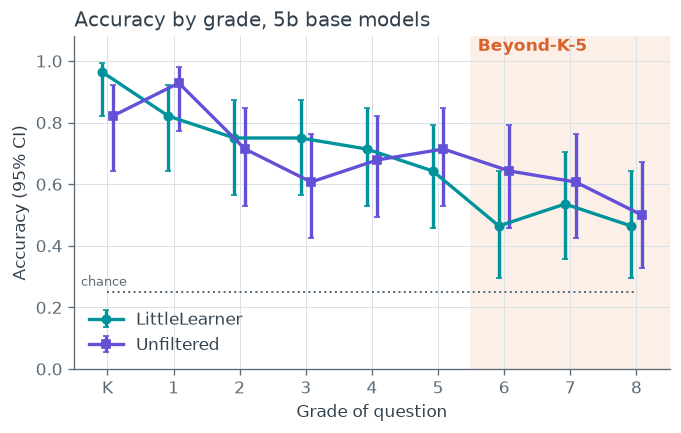

In [32]:
def plot_grade_curve(grade_acc, res, title=None):
    fig, ax = plt.subplots(figsize=(6.4, 3.6))
    grades = sorted(grade_acc.grade.unique())
    ax.axvspan(5.5, max(grades) + 0.5, color=ORANGE_BAND, zorder=0)
    ax.text(5.6, 1.02, "Beyond-K-5", color="#D9622B", fontweight="bold", va="bottom")
    chance = res.groupby("grade")["chance"].mean()
    ax.step(chance.index, chance.values, where="mid", color=MUTED, ls=":", lw=1.2)
    ax.text(grades[0] - 0.4, chance.iloc[0] + 0.02, "chance", color=MUTED, fontsize=8)
    offsets = {"LittleLearner": -0.08, "Unfiltered": 0.08}
    for m, g in grade_acc.groupby("model"):
        x = g.grade + offsets[m]
        ax.errorbar(x, g.acc, yerr=[g.acc - g.lo, g.hi - g.acc], color=MODEL_COLORS[m],
                    marker=MODEL_MARKERS[m], ms=5, lw=2, capsize=2, label=m)
    ax.set_xticks(grades, ["K" if g == 0 else str(g) for g in grades])
    ax.set_xlim(grades[0] - 0.5, grades[-1] + 0.5)
    ax.set_ylim(0, 1.08)
    ax.set_xlabel("Grade of question"); ax.set_ylabel("Accuracy (95% CI)")
    ax.legend(frameon=False, loc="lower left")
    ax.set_title(title or f"Accuracy by grade, {SIZE} base models", loc="left")
    return fig

fig = plot_grade_curve(grade_acc, res)
fig.savefig(FIG_DIR / f"grade_curve_{SIZE}.png"); plt.show()

## 5. Where does knowledge leak?

Beyond-K-5 items that LittleLearner gets right **with a clear margin** are leakage candidates. Items it gets right by a hair are probably luck. Look at them by topic.

In [34]:
LEAK_MARGIN = base.loc[base[METRIC], "margin_norm"].quantile(0.95)
print(f"LEAK_MARGIN = {LEAK_MARGIN:.2f}")

ll = res[res.model == "LittleLearner"]
leaks = ll[(ll.band == "BeyondK5") & ll[METRIC] & (ll.margin_norm > LEAK_MARGIN)]
print(f"{len(leaks)} confident Beyond-K-5 hits out of {(ll.band == 'BeyondK5').sum()}")
pd.set_option("display.max_colwidth", 120)
display(leaks.sort_values("margin_norm", ascending=False)[["id", "grade", "topic", "context", "options", "margin_norm"]])
display(ll.groupby(["band", "topic"])[METRIC].agg(["mean", "count"]).round(2))

LEAK_MARGIN = 0.70
6 confident Beyond-K-5 hits out of 84


,id,grade,topic,context,options,margin_norm
101,mat-g6-6_RP_A_3c-1,6,percent,Question: What is 10 percent of 200?\nAnswer:,"[ 20, 180, 210, 40]",1.924844
243,sci-g8-MS-PS2-1-99,8,forces,Question: Fill in the blank: Newton's third law says that for every action there is an equal and opposite ___.\nAnswer:,"[ mass, reaction, speed, motion]",1.907497
129,mat-g8-8_EE_A_2-1,8,roots,Question: What is the square root of 16?\nAnswer:,"[ 2, 8, 4, 5]",1.562500
103,mat-g6-6_RP_A_3c-3,6,percent,Question: What is 20 percent of 200?\nAnswer:,"[ 40, 160, 220, 80]",0.889253
130,mat-g8-8_EE_A_2-2,8,roots,Question: What is the square root of 196?\nAnswer:,"[ 15, 28, 98, 14]",0.791667
251,sci-g8-MS-ESS1-4-107,8,earth science,Question: About how old is Earth?\nAnswer:,"[ 460 years, 6 thousand years, 4.6 billion years, 46 million years]",0.724215


mean  count
band     topic                         
BeyondK5 earth science      1.00      6
         energy             0.33      3
         equations          0.00     12
         exponents          0.00      8
         forces             0.75      4
         geometry           0.25      4
         life science       0.77     13
         matter             1.00      6
         negative numbers   0.42     12
         percent            1.00      4
         probability        0.00      4
         roots              1.00      4
         space              0.00      2
         waves              0.50      2
K5       addition           0.81     16
         comparing numbers  1.00      4
         counting           1.00      4
         decimals           0.75      4
         division           1.00      4
         earth science      0.93     14
         energy             0.62      8
         exponents          0.00      4
         factors            0.75      4
         forces             0.50      6
         fractions          0.88      8
         geometry           0.50     16
         life science       0.95     22
         matter             0.89      9
         measurement        0.25      4
         multiplication     0.88      8
         place value        0.83     12
         space              1.00      6
         subtraction        0.50      8
         waves              0.86      7

## Scaling

Set `SIZE` to `"1.3b"` and `"5b"` and rerun sections 2-4. Scores are cached per model and size. The paper claims scale helps within K-5 and at the boundary but not beyond (Fig. 7), and this shows whether your items agree.

The cell below needs no model: it reads every size already in `cache/` and skips the rest. If H1 holds at scale, Unfiltered's Beyond-K-5 accuracy should rise with size while LittleLearner's stays flat, so the DiD grows.

,drop_LittleLearner,drop_Unfiltered,DiD,ci_low,ci_high
size,,,,,
0.6b,0.256,0.167,0.089,-0.030,0.208
1.3b,0.185,0.190,-0.006,-0.113,0.101
5b,0.286,0.161,0.125,0.006,0.238


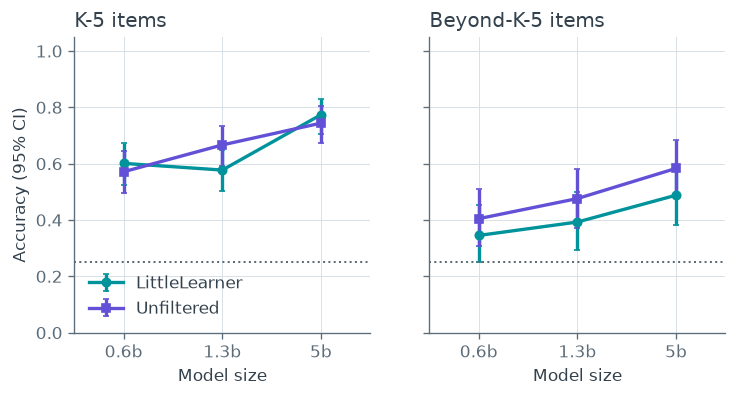

In [ ]:
SIZES = ["0.6b", "1.3b", "5b"]

def load_cached(size):
    # Rebuild `res` for one size from the score caches; None if either model is missing items at that size.
    parts = []
    for name in MODELS:
        path = CACHE_DIR / f"{name}_{size}.jsonl"
        recs = {r["id"]: r for r in map(json.loads, path.read_text().splitlines())} if path.exists() else {}
        if not set(items.id) <= set(recs):
            return None
        parts.append(pd.DataFrame([recs[i] for i in items.id]))
    return add_predictions(items, pd.concat(parts, ignore_index=True))

acc_rows, did_rows = [], []
for size in SIZES:
    r = load_cached(size)
    if r is None:
        print(f"{size}: not fully scored yet - skipping")
        continue
    g = r.groupby(["model", "band"])[METRIC].agg(["sum", "count"]).reset_index()
    g["acc"] = g["sum"] / g["count"] 

    g["lo"], g["hi"] = zip(*[wilson_ci(k, n) for k, n in zip(g["sum"], g["count"])])
    acc_rows.append(g.assign(size=size))
    drop, did, (lo, hi) = did_bootstrap(r)
    did_rows.append({"size": size, **{f"drop_{m}": v for m, v in drop.items()}, "DiD": did, "ci_low": lo, "ci_high": hi})

scaling = pd.concat(acc_rows, ignore_index=True)
display(pd.DataFrame(did_rows).set_index("size").round(3))

fig, axes = plt.subplots(1, 2, figsize=(7, 3.2), sharey=True)
done_sizes = scaling["size"].unique().tolist()
x = np.arange(len(done_sizes))
for ax, band, name in zip(axes, ["K5", "BeyondK5"], ["K-5 items", "Beyond-K-5 items"]):
    for m in MODELS:
        s = scaling[(scaling.model == m) & (scaling.band == band)].set_index("size").loc[done_sizes]
        ax.errorbar(x, s.acc, yerr=[s.acc - s.lo, s.hi - s.acc], color=MODEL_COLORS[m],
                    marker=MODEL_MARKERS[m], ms=5, lw=2, capsize=2, label=m)
    ax.axhline(res["chance"].mean(), color=MUTED, ls=":", lw=1.2)
    ax.set_xticks(x, done_sizes)
    ax.set_xlim(-0.5, len(done_sizes) - 0.5)
    ax.set_title(name, loc="left"); ax.set_xlabel("Model size")
axes[0].set_ylim(0, 1.05); axes[0].set_ylabel("Accuracy (95% CI)")
axes[0].legend(frameon=False, loc="lower left")
fig.savefig(FIG_DIR / "scaling.png"); plt.show()